In [ ]:
#importing all the necessary libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [ ]:
#running data set file
df=pd.read_csv("netflix.csv")

In [ ]:
#showing data set
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
#renaming the listed in column to genres

In [ ]:
df.rename(columns={"listed_in":"genre"},inplace=True)
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genre', 'description'],
      dtype='object')

In [ ]:
#dropping the show_id column as it may be of no use in the analysis

In [ ]:
df.drop(columns="show_id",inplace=True)

In [ ]:
#identical rows --- means by mistakes you enter same data for so many time it also can degrade
#the performance of analysis

In [ ]:
#checking up for duplicates

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#checking for the missing values

In [ ]:
df.isnull().sum()

,0
type,0
title,0
director,2518
cast,747
country,803
date_added,9
release_year,0
rating,4
duration,4
genre,1


In [ ]:
#here we can see clearly here some count are so big and some are so small
#which is avilable in less quantity we can drop them

In [ ]:
#if we write df.dropna()---all the rows having missing values got deleted
#if we write df.dropna(axis=1) the columns having missing values got declared

#if we want to delete missing valye from specific column
#df.dropna(subset=["column_name"],axis=1,inplace=True)

In [ ]:
df.shape

(8154, 11)

In [ ]:
#dropping the rows which have null values in date_added column as there are only 10 values which sums up to only 0.11% of the total values

In [ ]:
df.dropna(subset=['date_added'],inplace=True)
df['date_added'].isna().sum()

np.int64(0)

In [ ]:
#dropping the rows which hav null values in date_added column as there are only 4 values which sums up to only 0.05% of the total values

In [ ]:
df.dropna(subset=['rating'],inplace=True)
df['rating'].isna().sum()

np.int64(0)

In [ ]:
#dropping the rows which hav null values in date_added column as there are only 3 values which sums up to only 0.03% of the total values

In [ ]:
df.dropna(subset=['duration'],inplace=True)
df['duration'].isna().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
type,0
title,0
director,2506
cast,747
country,801
date_added,0
release_year,0
rating,0
duration,0
genre,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8137 entries, 0 to 8152
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   type          8137 non-null   object
 1   title         8137 non-null   object
 2   director      5631 non-null   object
 3   cast          7390 non-null   object
 4   country       7336 non-null   object
 5   date_added    8137 non-null   object
 6   release_year  8137 non-null   int64 
 7   rating        8137 non-null   object
 8   duration      8137 non-null   object
 9   genre         8137 non-null   object
 10  description   8137 non-null   object
dtypes: int64(1), object(10)
memory usage: 762.8+ KB


In [ ]:
#converting the date added column from object to date time format

In [ ]:
#when there is a missmatch in our date format then that value is replaced by null

df["date_added"]=pd.to_datetime(df["date_added"],errors='coerce')
df["date_added"].isna().sum()

np.int64(68)

In [ ]:
df.dropna(subset=["date_added"],inplace=True)
df['date_added'].isnull().sum()

np.int64(0)

In [ ]:
#adding day, month, year, month_name, day_name, as seprate columns to the dataframe as these will help us in analysis

In [ ]:
df['day']=df['date_added'].dt.day
df['month']=df['date_added'].dt.month
df['year']=df['date_added'].dt.year
df['month_name']=df['date_added'].dt.month_name()
df['weekday']=df['date_added'].dt.day_name()
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",24,9,2021,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,24,9,2021,September,Friday


In [ ]:
df['duration'].unique()

array(['90 min', '2 Seasons', '1 Season', '91 min', '125 min',
       '9 Seasons', '104 min', '127 min', '4 Seasons', '67 min', '94 min',
       '5 Seasons', '161 min', '61 min', '166 min', '147 min', '103 min',
       '97 min', '106 min', '111 min', '3 Seasons', '110 min', '105 min',
       '96 min', '124 min', '116 min', '98 min', '23 min', '115 min',
       '122 min', '99 min', '88 min', '100 min', '6 Seasons', '102 min',
       '93 min', '95 min', '85 min', '83 min', '113 min', '13 min',
       '182 min', '48 min', '145 min', '87 min', '92 min', '80 min',
       '117 min', '128 min', '119 min', '143 min', '114 min', '118 min',
       '108 min', '63 min', '121 min', '142 min', '154 min', '120 min',
       '82 min', '109 min', '101 min', '86 min', '229 min', '76 min',
       '89 min', '156 min', '112 min', '107 min', '129 min', '135 min',
       '136 min', '165 min', '150 min', '133 min', '70 min', '84 min',
       '140 min', '78 min', '7 Seasons', '64 min', '59 min', '139 min',
    

In [ ]:
s1='179 min'
int(s1.split()[0])

179

In [ ]:
s1='12 seasons'
int(s1.split()[0])

12

In [ ]:
df['duration']=df['duration'].apply(lambda x:int(x.split()[0]))

In [ ]:
df['duration'].unique()

array([ 90,   2,   1,  91, 125,   9, 104, 127,   4,  67,  94,   5, 161,
        61, 166, 147, 103,  97, 106, 111,   3, 110, 105,  96, 124, 116,
        98,  23, 115, 122,  99,  88, 100,   6, 102,  93,  95,  85,  83,
       113,  13, 182,  48, 145,  87,  92,  80, 117, 128, 119, 143, 114,
       118, 108,  63, 121, 142, 154, 120,  82, 109, 101,  86, 229,  76,
        89, 156, 112, 107, 129, 135, 136, 165, 150, 133,  70,  84, 140,
        78,   7,  64,  59, 139,  69, 148, 189, 141, 130, 138,  81, 132,
        10, 123,  65,  68,  66,  62,  74, 131,  39,  46,  38,   8,  17,
       126, 155, 159, 137,  12, 273,  36,  34,  77,  60,  49,  58,  72,
       204, 212,  25,  73,  29,  47,  32,  35,  71, 149,  33,  15,  54,
       224, 162,  37,  75,  79,  55, 158, 164, 173, 181, 185,  21,  24,
        51, 151,  42,  22, 134, 177,  52,  14,  53,  57,  28,  50,  26,
        45, 171,  27,  44, 146,  20, 157, 203,  41,  30, 194, 233, 237,
       230, 195, 253, 152, 190, 160, 208, 180, 144, 174, 170, 19

In [ ]:
#checking for unique values of rating and categorising them for better understanding

In [ ]:
df['rating'].unique()

array(['PG-13', 'TV-MA', 'PG', 'TV-14', 'TV-PG', 'TV-Y', 'TV-Y7', 'R',
       'TV-G', 'G', 'NC-17', 'NR', 'TV-Y7-FV', 'UR'], dtype=object)

In [ ]:
#netflix has officially categorised these into 3 main categories so we are using that for our EDA---Exploratory Data Analysis

In [ ]:
df['rating']=df['rating'].replace(['TV-Y','TV-Y7','G','TV-G','PG','TV-PG','TV-Y7-FV'],'kids')
df['rating']=df['rating'].replace(['PG-13','TV-14'],'Teens')
df['rating']=df['rating'].replace(['R','TV-MA','NC-17'],'Adults')
df['rating']=df['rating'].replace(['NR','UR'],np.nan)
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,Teens,90,Documentaries,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,Adults,1,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,24,9,2021,September,Friday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,Adults,1,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",24,9,2021,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,Adults,2,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,24,9,2021,September,Friday


In [ ]:
df['rating'].unique()

array(['Teens', 'Adults', 'kids', nan], dtype=object)

In [ ]:
#from here it is confirmed that values have been replaced successfully and now we will delete rows that have null values

In [ ]:
df['rating'].isna().sum()

np.int64(66)

In [ ]:
df.dropna(subset=['rating'],inplace=True)
df['rating'].isna().sum()

np.int64(0)

In [ ]:
#81 values were null, which was only about 1% of the data, so we deleted those rows

In [ ]:
df.isna().sum()

,0
type,0
title,0
director,2441
cast,726
country,798
date_added,0
release_year,0
rating,0
duration,0
genre,0


In [ ]:
#now we still have about 48% missing data so we will check in which rows the director , country and cast all three are null, if all these 3 are null then there is no use of that row

In [ ]:
df[(df['director'].isna()) & (df['country'].isna()) & (df['cast'].isna())].shape[0]

93

In [ ]:
#we found out that total 96 such rows are there which dont have director, country and cast as null, so deleting those rows

In [ ]:
df.shape

(8003, 16)

In [ ]:
df.dropna(subset=['director','country','cast'],how='all',inplace=True)
df.shape

(7910, 16)

In [ ]:
df.isna().sum()

,0
type,0
title,0
director,2348
cast,633
country,705
date_added,0
release_year,0
rating,0
duration,0
genre,0


In [ ]:
df.isna().sum()

,0
type,0
title,0
director,2348
cast,633
country,705
date_added,0
release_year,0
rating,0
duration,0
genre,0


In [ ]:
#as the missing value percentage of these rows are significant, we cant delete them so we will deal with those later and now lets focus
#on more major problems in the data set ehich is nested data in director, cast, country and genre

In [ ]:
df['cast'][2]

'Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera'

In [ ]:
df_cast=pd.DataFrame(df['cast'].apply(lambda x:str(x).split(', ')).tolist(),index=df['title'])
df_cast

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
title,,,,,,,,,,,,,,,,,,,,,
Dick Johnson Is Dead,nan,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
Blood & Water,Ama Qamata,Khosi Ngema,Gail Mabalane,Thabang Molaba,Dillon Windvogel,Natasha Thahane,Arno Greeff,Xolile Tshabalala,Getmore Sithole,Cindy Mahlangu,...,None,None,None,None,None,None,None,None,None,None
Ganglands,Sami Bouajila,Tracy Gotoas,Samuel Jouy,Nabiha Akkari,Sofia Lesaffre,Salim Kechiouche,Noureddine Farihi,Geert Van Rampelberg,Bakary Diombera,None,...,None,None,None,None,None,None,None,None,None,None
Kota Factory,Mayur More,Jitendra Kumar,Ranjan Raj,Alam Khan,Ahsaas Channa,Revathi Pillai,Urvi Singh,Arun Kumar,None,None,...,None,None,None,None,None,None,None,None,None,None
Midnight Mass,Kate Siegel,Zach Gilford,Hamish Linklater,Henry Thomas,Kristin Lehman,Samantha Sloyan,Igby Rigney,Rahul Kohli,Annarah Cymone,Annabeth Gish,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Tales of the City (1993),Olympia Dukakis,Donald Moffat,Laura Linney,Marcus D'Amico,Billy Campbell,Thomas Gibson,Paul Gross,Barbara Garrick,Chloe Webb,Nina Foch,...,None,None,None,None,None,None,None,None,None,None
Tamanchey,Nikhil Dwivedi,Richa Chadha,Damandeep Singh Baggan,Vijay Pande,Talib Mehdi,Tushar Phulke,Mahesh Gupta,Prasad Labhe,None,None,...,None,None,None,None,None,None,None,None,None,None
Tarif de nuit,Jonathan Howard,Jonathan Demurger,Fanny Valette,Jess Liaudin,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None


In [ ]:
df_cast=df_cast.stack()
df_cast

title                  
Dick Johnson Is Dead  0                nan
Blood & Water         0         Ama Qamata
                      1        Khosi Ngema
                      2      Gail Mabalane
                      3     Thabang Molaba
                                ...       
Tarzan 2              4     Estelle Harris
                      5        Glenn Close
                      6    Lance Henriksen
                      7       Brenda Grate
                      8      Harrison Fahn
Length: 59039, dtype: object

In [ ]:
df_cast=pd.DataFrame(df_cast)
df_cast

0
title                                  
Dick Johnson Is Dead 0              nan
Blood & Water        0       Ama Qamata
                     1      Khosi Ngema
                     2    Gail Mabalane
                     3   Thabang Molaba
...                                 ...
Tarzan 2             4   Estelle Harris
                     5      Glenn Close
                     6  Lance Henriksen
                     7     Brenda Grate
                     8    Harrison Fahn

[59039 rows x 1 columns]

In [ ]:
df_cast.reset_index(inplace=True)
df_cast

,title,level_1,0
0,Dick Johnson Is Dead,0,nan
1,Blood & Water,0,Ama Qamata
2,Blood & Water,1,Khosi Ngema
3,Blood & Water,2,Gail Mabalane
4,Blood & Water,3,Thabang Molaba
...,...,...,...
59034,Tarzan 2,4,Estelle Harris
59035,Tarzan 2,5,Glenn Close
59036,Tarzan 2,6,Lance Henriksen
59037,Tarzan 2,7,Brenda Grate


In [ ]:
df_cast=df_cast[["title",0]]
df_cast

,title,0
0,Dick Johnson Is Dead,nan
1,Blood & Water,Ama Qamata
2,Blood & Water,Khosi Ngema
3,Blood & Water,Gail Mabalane
4,Blood & Water,Thabang Molaba
...,...,...
59034,Tarzan 2,Estelle Harris
59035,Tarzan 2,Glenn Close
59036,Tarzan 2,Lance Henriksen
59037,Tarzan 2,Brenda Grate


In [ ]:
df_cast.columns=['title','cast']
df_cast

,title,cast
0,Dick Johnson Is Dead,nan
1,Blood & Water,Ama Qamata
2,Blood & Water,Khosi Ngema
3,Blood & Water,Gail Mabalane
4,Blood & Water,Thabang Molaba
...,...,...
59034,Tarzan 2,Estelle Harris
59035,Tarzan 2,Glenn Close
59036,Tarzan 2,Lance Henriksen
59037,Tarzan 2,Brenda Grate


In [ ]:
df_cast.replace('nan',np.nan,inplace=True)
df_cast.isna().sum()

/tmp/ipykernel_8895/154984155.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cast.replace('nan',np.nan,inplace=True)


,0
title,0
cast,633


In [ ]:
#now we will split all the nested data individually and save them in a new dataframe, and then we will merge all of them so get the final dataframe
#in the process we will lose the format of null values from np.NaN to string NaN, so thhat requires one additional step which is done
#in the last 2 lines of each block we can confirm the count of null values from the above block

In [ ]:
df_genre=pd.DataFrame(df['genre'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_genre=df_genre.stack()
df_genre=pd.DataFrame(df_genre)
df_genre.reset_index(inplace=True)
df_genre=df_genre[['title',0]]
df_genre.columns=['title','genre']
df_genre.replace('nan',np.nan,inplace=True)
df_genre.isna().sum()

,0
title,0
genre,0


In [ ]:
df.columns

Index(['type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genre', 'description', 'day',
       'month', 'year', 'month_name', 'weekday'],
      dtype='object')

In [ ]:
df_director=pd.DataFrame(df['director'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_director=df_director.stack()
df_director=pd.DataFrame(df_director)
df_director.reset_index(inplace=True)
df_director=df_director[['title',0]]
df_director.columns=['title','director']
df_director.replace('nan',np.nan,inplace=True)
df_director.isna().sum()

,0
title,0
director,2348


In [ ]:
df_country=pd.DataFrame(df['country'].apply(lambda x: str(x).split(', ')).tolist(),index=df['title'])
df_country=df_country.stack()
df_country=pd.DataFrame(df_country)
df_country.reset_index(inplace=True)
df_country=df_country[['title',0]]
df_country.columns=['title','country']
df_country.replace('nan',np.nan,inplace=True)
df_country.isna().sum()

,0
title,0
country,705


In [ ]:
df12=df_cast.merge(df_genre,on='title')
df12

,title,cast,genre
0,Dick Johnson Is Dead,NaN,Documentaries
1,Blood & Water,Ama Qamata,International TV Shows
2,Blood & Water,Ama Qamata,TV Dramas
3,Blood & Water,Ama Qamata,TV Mysteries
4,Blood & Water,Khosi Ngema,International TV Shows
...,...,...,...
136518,Tarzan 2,Estelle Harris,Children & Family Movies
136519,Tarzan 2,Glenn Close,Children & Family Movies
136520,Tarzan 2,Lance Henriksen,Children & Family Movies
136521,Tarzan 2,Brenda Grate,Children & Family Movies


In [ ]:
df123=df_director.merge(df12,on='title')
df123

,title,director,cast,genre
0,Dick Johnson Is Dead,Kirsten Johnson,NaN,Documentaries
1,Blood & Water,NaN,Ama Qamata,International TV Shows
2,Blood & Water,NaN,Ama Qamata,TV Dramas
3,Blood & Water,NaN,Ama Qamata,TV Mysteries
4,Blood & Water,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...
147293,Tarzan 2,Brian Smith,Estelle Harris,Children & Family Movies
147294,Tarzan 2,Brian Smith,Glenn Close,Children & Family Movies
147295,Tarzan 2,Brian Smith,Lance Henriksen,Children & Family Movies
147296,Tarzan 2,Brian Smith,Brenda Grate,Children & Family Movies


In [ ]:
df1234=df_country.merge(df123,on='title')
df1234

,title,country,director,cast,genre
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries
1,Blood & Water,South Africa,NaN,Ama Qamata,International TV Shows
2,Blood & Water,South Africa,NaN,Ama Qamata,TV Dramas
3,Blood & Water,South Africa,NaN,Ama Qamata,TV Mysteries
4,Blood & Water,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...
183311,Tarzan 2,United States,Brian Smith,Estelle Harris,Children & Family Movies
183312,Tarzan 2,United States,Brian Smith,Glenn Close,Children & Family Movies
183313,Tarzan 2,United States,Brian Smith,Lance Henriksen,Children & Family Movies
183314,Tarzan 2,United States,Brian Smith,Brenda Grate,Children & Family Movies


In [ ]:
df_new=df.merge(df1234,on='title')
df_new

,type,title,director_x,cast_x,country_x,date_added,release_year,rating,duration,genre_x,description,day,month,year,month_name,weekday,country_y,director_y,cast_y,genre_y
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,Teens,90,Documentaries,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183311,Movie,Tarzan 2,Brian Smith,"Harrison Chad, George Carlin, Brad Garrett, Ro...",United States,2017-06-23,2005,kids,72,Children & Family Movies,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Estelle Harris,Children & Family Movies
183312,Movie,Tarzan 2,Brian Smith,"Harrison Chad, George Carlin, Brad Garrett, Ro...",United States,2017-06-23,2005,kids,72,Children & Family Movies,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Glenn Close,Children & Family Movies
183313,Movie,Tarzan 2,Brian Smith,"Harrison Chad, George Carlin, Brad Garrett, Ro...",United States,2017-06-23,2005,kids,72,Children & Family Movies,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Lance Henriksen,Children & Family Movies
183314,Movie,Tarzan 2,Brian Smith,"Harrison Chad, George Carlin, Brad Garrett, Ro...",United States,2017-06-23,2005,kids,72,Children & Family Movies,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Brenda Grate,Children & Family Movies


In [ ]:
df_new.drop(columns=['cast_x','country_x','director_x','genre_x'],inplace=True)
df_new

,type,title,date_added,release_year,rating,duration,description,day,month,year,month_name,weekday,country_y,director_y,cast_y,genre_y
0,Movie,Dick Johnson Is Dead,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183311,Movie,Tarzan 2,2017-06-23,2005,kids,72,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Estelle Harris,Children & Family Movies
183312,Movie,Tarzan 2,2017-06-23,2005,kids,72,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Glenn Close,Children & Family Movies
183313,Movie,Tarzan 2,2017-06-23,2005,kids,72,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Lance Henriksen,Children & Family Movies
183314,Movie,Tarzan 2,2017-06-23,2005,kids,72,How did the King of the Jungle ascend to the t...,23,6,2017,June,Friday,United States,Brian Smith,Brenda Grate,Children & Family Movies


In [ ]:
df_new.rename(columns={'country_y':'country','director_y':'director','cast_y':'cast','genre_y':'genre'},inplace=True)

In [ ]:
df_new.head()

,type,title,date_added,release_year,rating,duration,description,day,month,year,month_name,weekday,country,director,cast,genre
0,Movie,Dick Johnson Is Dead,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows


In [ ]:
df_new.shape

(183316, 16)

In [ ]:
#this is the new dataframe which has 198404 rows and 16 columns after unnesting the data
#here we woll not delete the missing values as it will affect the data and other columns will get manipulated, hence we will  replace
#them with a global value 'unknown'

In [ ]:
df_new['cast']=df_new['cast'].replace(np.nan,'unknown')
df_new['country']=df_new['country'].replace(np.nan,'unknown')
df_new['director']=df_new['director'].replace(np.nan,'unknown')

In [ ]:
df_new.head()

,type,title,date_added,release_year,rating,duration,description,day,month,year,month_name,weekday,country,director,cast,genre
0,Movie,Dick Johnson Is Dead,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",25,9,2021,September,Saturday,United States,Kirsten Johnson,unknown,Documentaries
1,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,unknown,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,unknown,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,unknown,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",24,9,2021,September,Friday,South Africa,unknown,Khosi Ngema,International TV Shows


In [ ]:
#after replacong we can confirm no more null values

In [ ]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183316 entries, 0 to 183315
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   type          183316 non-null  object        
 1   title         183316 non-null  object        
 2   date_added    183316 non-null  datetime64[ns]
 3   release_year  183316 non-null  int64         
 4   rating        183316 non-null  object        
 5   duration      183316 non-null  int64         
 6   description   183316 non-null  object        
 7   day           183316 non-null  int32         
 8   month         183316 non-null  int32         
 9   year          183316 non-null  int32         
 10  month_name    183316 non-null  object        
 11  weekday       183316 non-null  object        
 12  country       183316 non-null  object        
 13  director      183316 non-null  object        
 14  cast          183316 non-null  object        
 15  genre         183

In [ ]:
df_new.drop(['description'],axis=1,inplace=True)

In [ ]:
df_new.duplicated().sum()

np.int64(55)

In [ ]:
#in the new dataframe, we can see 55 rows which are duplicated, so deleting them

In [ ]:
df_new.drop_duplicates(keep='first',inplace=True)

In [ ]:
#creating 2 more dataframes for better analysis by dividing the present dataframe on the basis pf type i.e Movie and TV Show and moving them df_movies and df_tvs#

In [ ]:
df_movies=df_new[df_new['type']=='Movie']
df_tvs=df_new[df_new['type']=='TV Show']

In [ ]:
df_movies.shape

(130388, 15)

In [ ]:
df_tvs.shape

(52873, 15)

In [ ]:
#the duration column has values such as 90 minutes for movied and 2 seasons for tv shows, so we will remove the word 'minutes' and 'seasons' in their respective dataframes
#here, we are placing the column duration with a better name season for tv shows only in df_tvs

In [ ]:
df_tvs.rename(columns={'duration':'seasons'},inplace=True)

/tmp/ipykernel_8895/3221938497.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tvs.rename(columns={'duration':'seasons'},inplace=True)


In [ ]:
#we are ready with out dataframes, and also redy to begin our EDA---Exploratory Data Analysis

In [ ]:
#lets start with checking the time period of our data

In [ ]:
print(df['year'].min())
print(df['year'].max())

#the data lies between the year 2008 and 2021

2008
2021


In [ ]:
#now lets count of content available on Netflix.

In [ ]:
df.shape[0]

#the netflix library has 8525 movies or shows to watch

7910

In [ ]:
#now lets see the count of movies and TV Shows individually

In [ ]:
print('Movie', df[df['type']=='Movie'].shape[0])
print('TV Show', df[df['type']=='TV Show'].shape[0])

#there are total 6031 movies and 2494 TV Shows to watch

Movie 5510
TV Show 2400


In [ ]:
#now lets see the count of directors present

In [ ]:
df_director['director'].nunique()

#there are a total of 4921 directors present in the data

4537

In [ ]:
#now, lets see the count of actors present

In [ ]:
df_cast['cast'].nunique()

#there are a lot of 35892 actors present in the data

34059

In [ ]:
#lets check in how many countries in the data distributed in

In [ ]:
df_country['country'].nunique()

#the content is distributed across 127 countries

118

In [ ]:
#Lets start our visualization with seeing the distribution of content on netflix.
#here we will use df as we only need to count he row once.

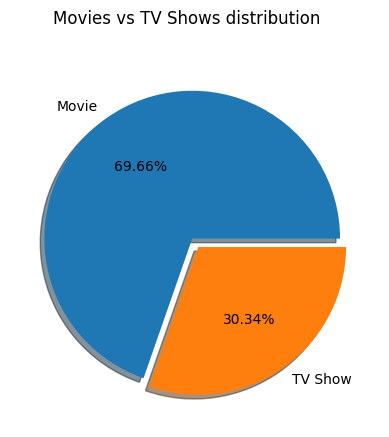

In [ ]:
plt.pie(df["type"].value_counts(),labels=df["type"].value_counts().index,
        autopct="%1.2f%%",explode=[0.03,0.04],shadow=True)
plt.suptitle('Movies vs TV Shows distribution')   #sup title--- super title
plt.show()

In [ ]:
df_temp=df_new.drop_duplicates(subset=['country','title'])
df_temp

,type,title,date_added,release_year,rating,duration,day,month,year,month_name,weekday,country,director,cast,genre
0,Movie,Dick Johnson Is Dead,2021-09-25,2020,Teens,90,25,9,2021,September,Saturday,United States,Kirsten Johnson,unknown,Documentaries
1,TV Show,Blood & Water,2021-09-24,2021,Adults,2,24,9,2021,September,Friday,South Africa,unknown,Ama Qamata,International TV Shows
58,TV Show,Ganglands,2021-09-24,2021,Adults,1,24,9,2021,September,Friday,unknown,Julien Leclercq,Sami Bouajila,Crime TV Shows
85,TV Show,Kota Factory,2021-09-24,2021,Adults,2,24,9,2021,September,Friday,India,unknown,Mayur More,International TV Shows
109,TV Show,Midnight Mass,2021-09-24,2021,Adults,1,24,9,2021,September,Friday,unknown,Mike Flanagan,Kate Siegel,TV Dramas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183245,TV Show,Tales of the City (1993),2019-06-28,1993,Adults,1,28,6,2019,June,Friday,United States,unknown,Olympia Dukakis,TV Dramas
183257,Movie,Tamanchey,2017-10-15,2014,Adults,111,15,10,2017,October,Sunday,India,Navneet Behal,Nikhil Dwivedi,Action & Adventure
183281,Movie,Tarif de nuit,2018-03-01,2015,Adults,81,1,3,2018,March,Thursday,France,Julien Seri,Jonathan Howard,International Movies
183289,Movie,Tarzan,2018-06-23,1999,kids,89,23,6,2018,June,Saturday,United States,Chris Buck,Tony Goldwyn,Children & Family Movies


In [ ]:
x=df_temp['country'].value_counts().head(10)
x

,count
country,
United States,3257
India,981
unknown,705
United Kingdom,670
Canada,383
France,357
Japan,305
Spain,219
South Korea,212


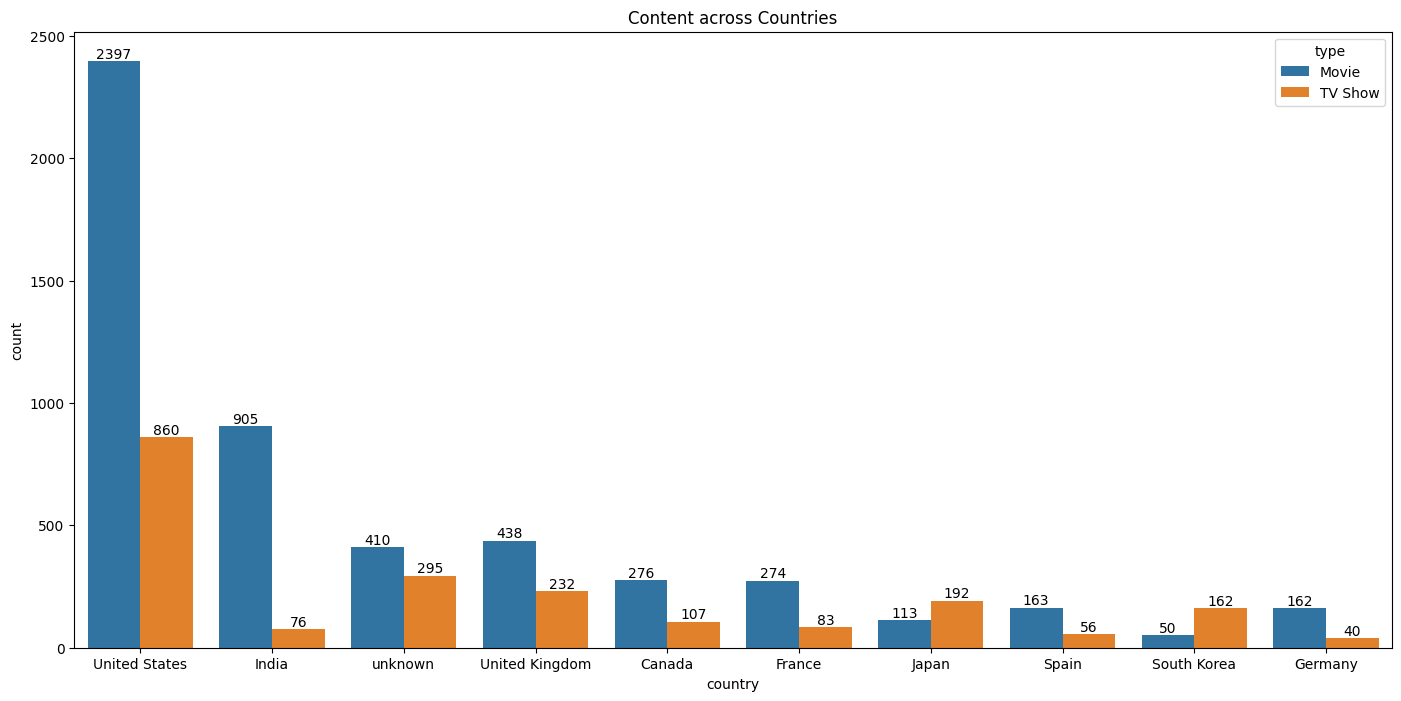

In [ ]:
plt.figure(figsize=(17,8))
plt.title('Content across Countries')
label=sns.countplot(data=df_temp, x='country',hue='type',order=x.index)
for i in label.containers:
  label.bar_label(i)
plt.show()

/tmp/ipykernel_8895/258031016.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='director', order = x.index,palette="husl")
/tmp/ipykernel_8895/258031016.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_tvs_temp, x='director', order = y.index,palette="husl")


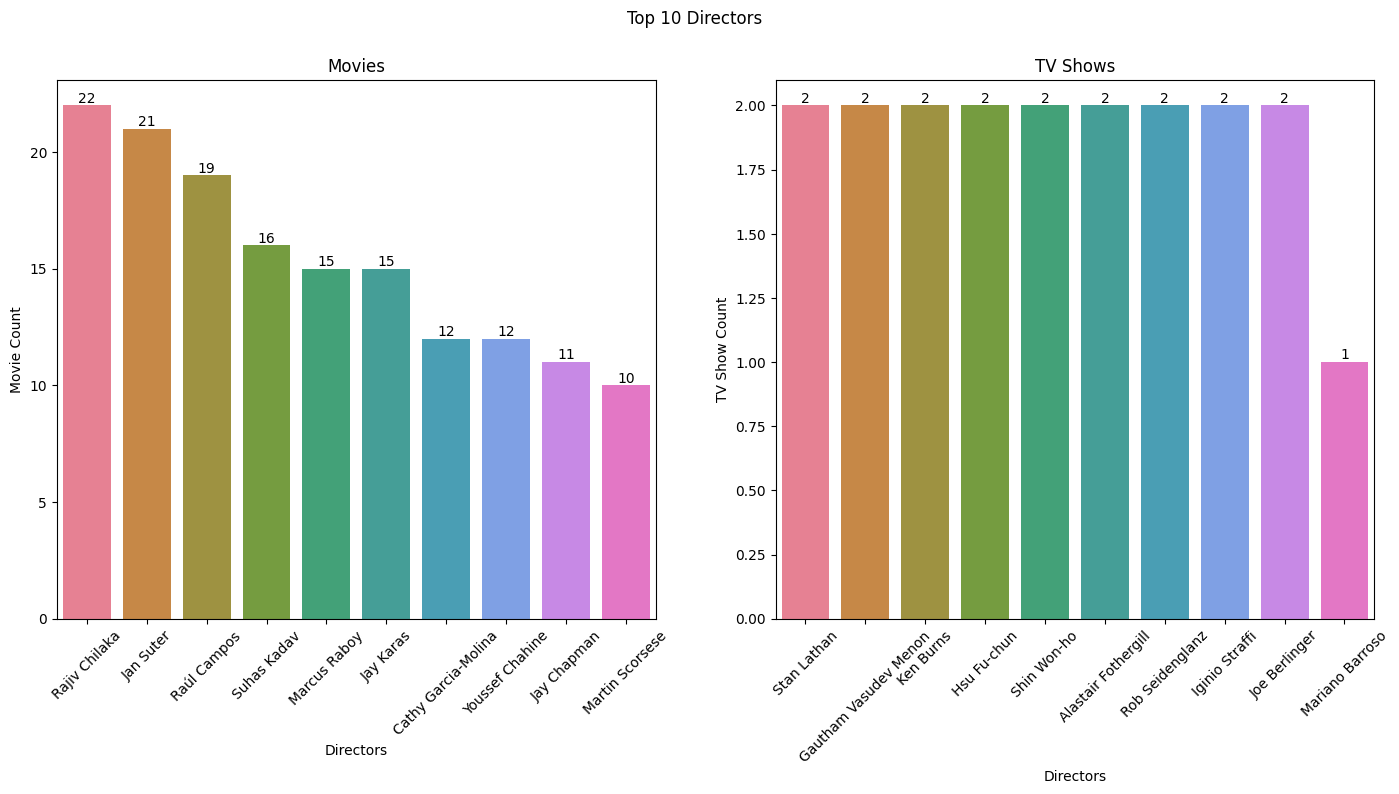

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['director','title'])
df_tvs_temp = df_tvs.drop_duplicates(subset = ['director','title'])
plt.figure(figsize = (17,7))
plt.suptitle('Top 10 Directors')
plt.subplot(1,2,1)
x=df_movies_temp['director'].value_counts()[1:11]
label = sns.countplot(data=df_movies_temp, x='director', order = x.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("Movies")
plt.xticks(rotation=45)
plt.xlabel('Directors')
plt.ylabel('Movie Count')
plt.subplot(1,2,2)
y=df_tvs_temp['director'].value_counts()[1:11]
label = sns.countplot(data=df_tvs_temp, x='director', order = y.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("TV Shows")
plt.xticks(rotation=45)
plt.xlabel('Directors')
plt.ylabel('TV Show Count')
plt.show()

/tmp/ipykernel_8895/1952427153.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='genre', order = x.index,palette="husl")
/tmp/ipykernel_8895/1952427153.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_tvs_temp, x='genre', order = y.index,palette="husl")


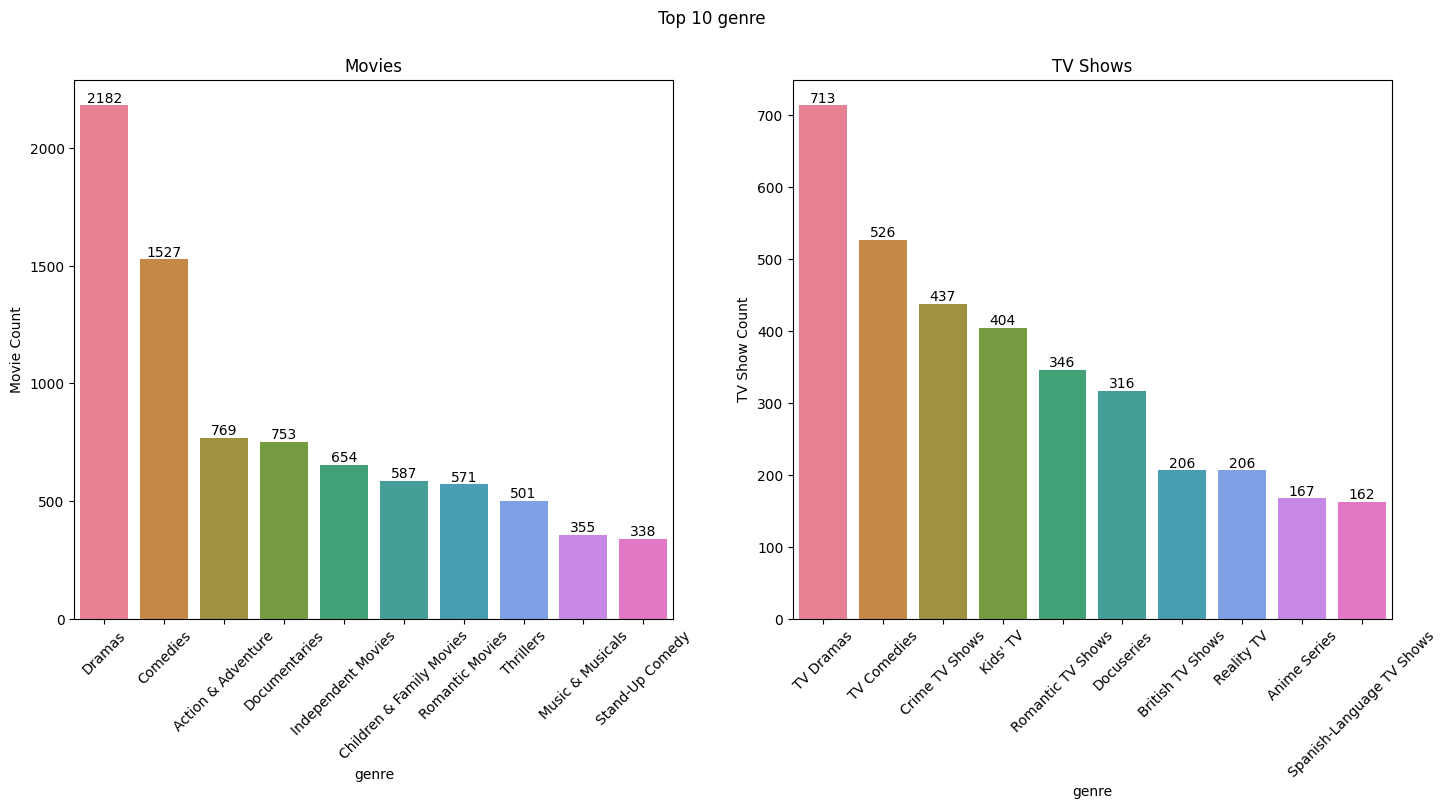

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['genre','title'])
df_tvs_temp = df_tvs.drop_duplicates(subset = ['genre','title'])
plt.figure(figsize = (17,7))
plt.suptitle('Top 10 genre')
plt.subplot(1,2,1)
x=df_movies_temp['genre'].value_counts()[1:11]
label = sns.countplot(data=df_movies_temp, x='genre', order = x.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("Movies")
plt.xticks(rotation=45)
plt.xlabel('genre')
plt.ylabel('Movie Count')
plt.subplot(1,2,2)
y=df_tvs_temp['genre'].value_counts()[1:11]
label = sns.countplot(data=df_tvs_temp, x='genre', order = y.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("TV Shows")
plt.xticks(rotation=45)
plt.xlabel('genre')
plt.ylabel('TV Show Count')
plt.show()

/tmp/ipykernel_8895/1285775171.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='cast', order = x.index,palette="husl")
/tmp/ipykernel_8895/1285775171.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_tvs_temp, x='cast', order = y.index,palette="husl")


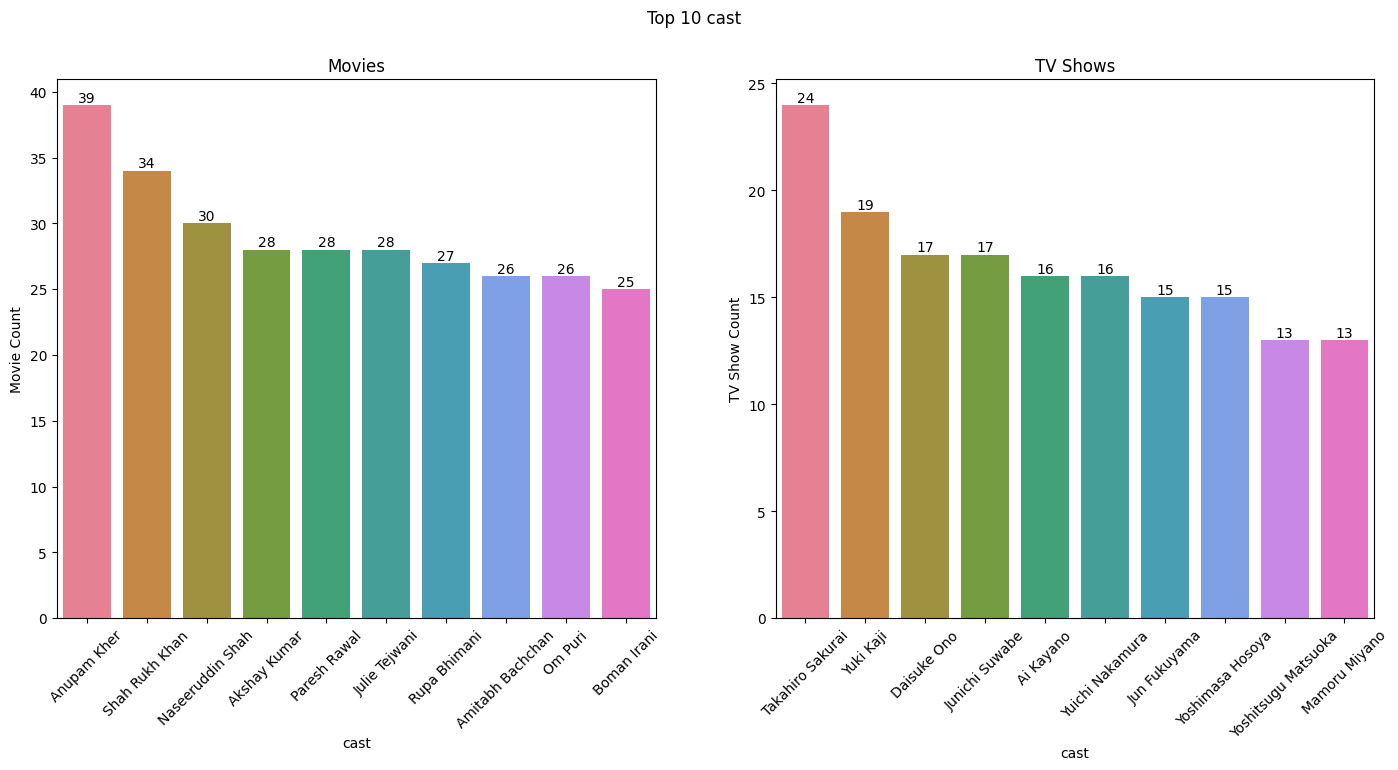

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['cast','title'])
df_tvs_temp = df_tvs.drop_duplicates(subset = ['cast','title'])
plt.figure(figsize = (17,7))
plt.suptitle('Top 10 cast')
plt.subplot(1,2,1)
x=df_movies_temp['cast'].value_counts()[1:11]
label = sns.countplot(data=df_movies_temp, x='cast', order = x.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("Movies")
plt.xticks(rotation=45)
plt.xlabel('cast')
plt.ylabel('Movie Count')
plt.subplot(1,2,2)
y=df_tvs_temp['cast'].value_counts()[1:11]
label = sns.countplot(data=df_tvs_temp, x='cast', order = y.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("TV Shows")
plt.xticks(rotation=45)
plt.xlabel('cast')
plt.ylabel('TV Show Count')
plt.show()

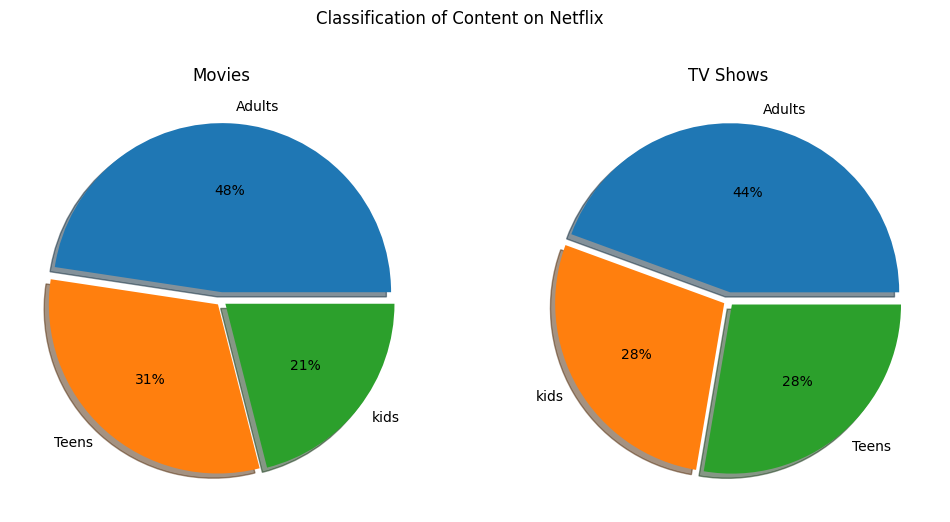

In [ ]:
df_movies_temp = df_movies.drop_duplicates (subset = ['rating', 'title'])
df_tvs_temp = df_tvs.drop_duplicates (subset = ['rating', 'title'])
plt.figure(figsize = (12,6))
plt.suptitle('Classification of Content on Netflix')
plt.subplot(1,2,1)
plt.pie(df_movies_temp['rating'].value_counts(),
labels = df_movies_temp['rating'].value_counts().index,
autopct='%0.0f%%', explode = (0.05,0.03,0.03), shadow = True)
plt.title('Movies')
plt.subplot(1,2,2)
plt.pie(df_tvs_temp['rating'].value_counts(),
labels = df_tvs_temp['rating'].value_counts().index,
autopct='%0.0f%%', explode = (0.05,0.03,0.03), shadow = True)
plt.title('TV Shows')
plt.show()

/tmp/ipykernel_8895/3616948528.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='year', order = mv_year.index,palette="viridis")
/tmp/ipykernel_8895/3616948528.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='month_name',
/tmp/ipykernel_8895/3616948528.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='weekday',


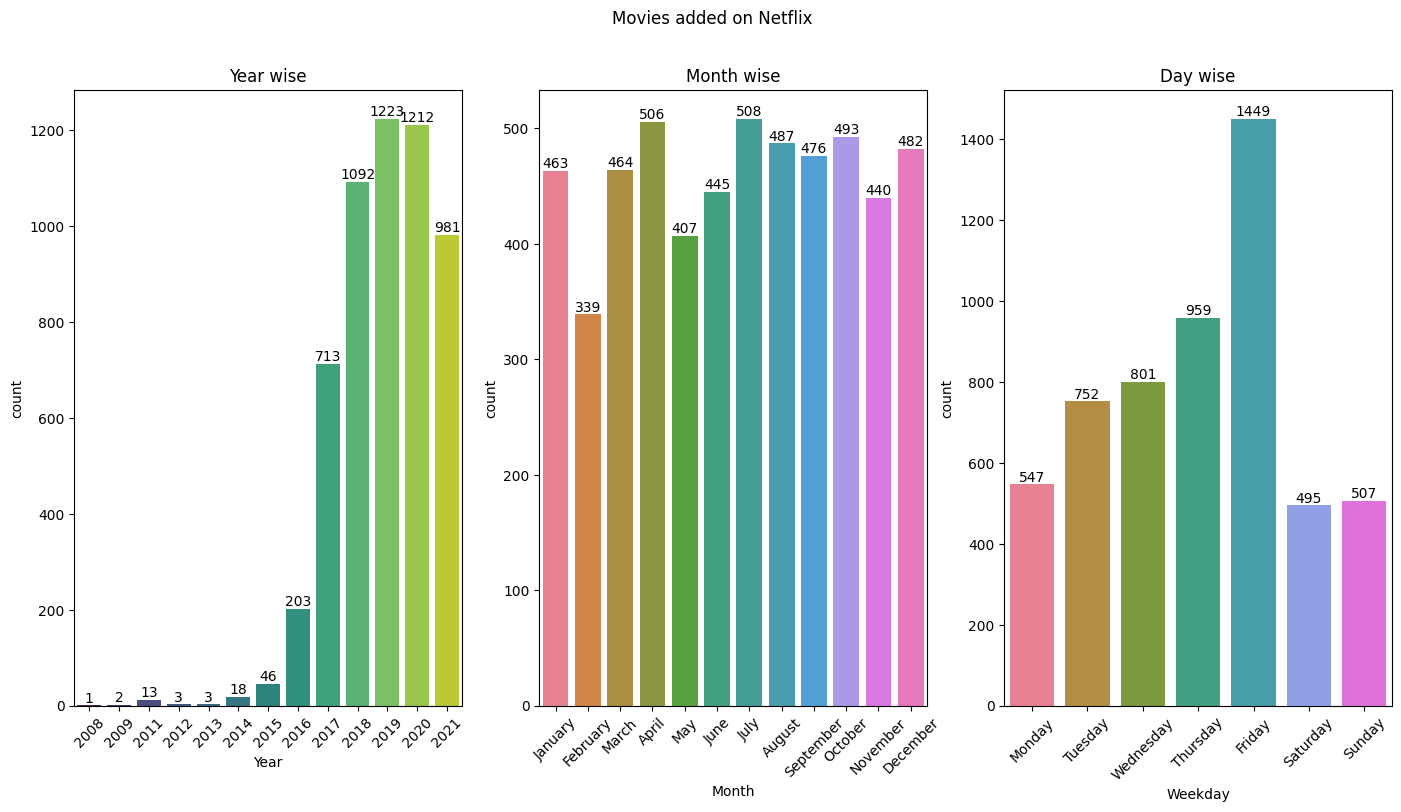

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['year','title'])
df_movies_temp
mv_year = df_movies_temp['year'].value_counts()
mv_year.sort_index(inplace=True)
mv_year
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July','August', 'September',
               'October', 'November', 'December']
mv_month = df_movies_temp['month_name'].value_counts().loc[month_order]
mv_month
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
mv_day = df_movies_temp['weekday'].value_counts().loc[day_order]
mv_day
plt.figure(figsize=(17,8))
plt.suptitle('Movies added on Netflix')
plt.subplot(1,3,1)
label = sns.countplot(data=df_movies_temp, x='year', order = mv_year.index,palette="viridis")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.title('Year wise')
plt.subplot(1,3,2)
label = sns.countplot(data=df_movies_temp, x='month_name',
                      order = mv_month.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.title('Month wise')

plt.subplot(1,3,3)
label = sns.countplot(data=df_movies_temp, x='weekday',
                      order = mv_day.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Weekday')
plt.title('Day wise')
plt.show()

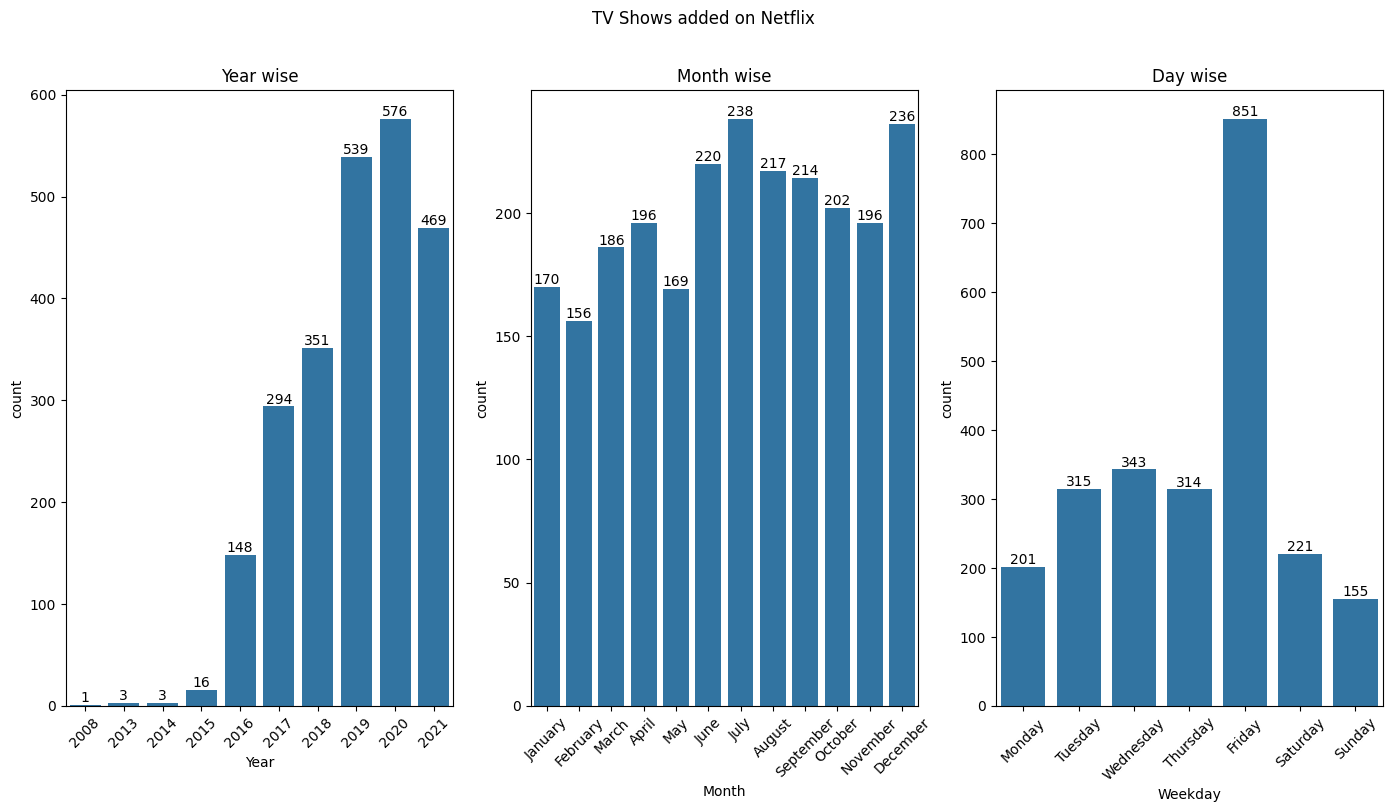

In [ ]:
df_tvs_temp = df_tvs.drop_duplicates(subset = ['year','title'])
tv_year = df_tvs_temp['year'].value_counts()
tv_year.sort_index(inplace=True)
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July','August', 'September', 'October', 'November', 'December']
tv_month = df_tvs_temp['month_name'].value_counts().loc[month_order]
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
tv_day = df_tvs_temp['weekday'].value_counts().loc[day_order]
plt.figure(figsize=(17,8))
plt.suptitle('TV Shows added on Netflix')
plt.subplot(1,3,1)
label = sns.countplot(data=df_tvs_temp, x='year', order = tv_year.index)
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.title('Year wise')
plt.subplot(1,3,2)
label = sns.countplot(data=df_tvs_temp, x='month_name', order = tv_month.index)
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.title('Month wise')
plt.subplot(1,3,3)
label = sns.countplot(data=df_tvs_temp, x='weekday', order = tv_day.index)
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Weekday')
plt.title('Day wise')
plt.show()